In [12]:
import pandas as pd
import numpy as np
from scipy.stats import norm
import ipynbname
import matplotlib.pyplot as plt

# General

In [8]:
def burden_analysis(mut_type, c_case, c_control, case_furaw, control_furaw):
    rate_case = c_case / case_furaw
    rate_control = c_control / control_furaw
    fc = rate_case / rate_control
    print(mut_type, fc)
    return fc

In [ ]:
folder_path = str(ipynbname.path().parent) + "/"
print(folder_path)

# Get Fu's raw count table

In [ ]:
fu_sup_tables = f"{folder_path}ref/Fu_NatGen_2022/NIHMS1844621-supplement-Supplementary_Table.xlsx"
df_asc_ssc = pd.read_excel(fu_sup_tables, sheet_name="Supplementary Table 5").dropna(subset = "chromosome")
df_asc_ssc = df_asc_ssc.drop(columns = {"dn.syn", 'dn.syn.sib', 'in.t.syn', 'in.u.syn', 'dn.mis', 'dn.mis.sib', 'in.t.mis.all', 'in.u.mis.all'})
df_asc_ssc

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,...,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,3.0,...,0.0,0.0,0.0,0.0,0.0,0.0,3.0,3.0,8.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,9.0,5.0,20.0,20.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,2.0,6.0,6.0,7.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,0.0,...,2.0,0.0,0.0,0.0,1.0,1.0,9.0,5.0,38.0,27.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,14.0,22.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,0.0,...,0.0,0.0,1.0,1.0,23.0,11.0,1.0,0.0,16.0,15.0


In [96]:
df_spark = pd.read_excel(fu_sup_tables, sheet_name="Supplementary Table 6").dropna(subset = "chromosome")
df_spark = df_spark.drop(columns = {"dn.syn", 'dn.syn.sib', 'in.t.syn', 'in.u.syn', 'dn.mis', 'dn.mis.sib', 'in.t.mis.all', 'in.u.mis.all'})
df_spark

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,dn.ptv,...,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000009,3.723593e-06,0.000003,4.0,...,0.0,0.0,0.0,0.0,0.0,0.0,3.0,1.0,3.0,2.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000018,2.083765e-05,0.000019,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,10.0,10.0,17.0,17.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000009,1.384912e-05,0.000015,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,2.0,3.0,5.0,14.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000013,1.621584e-05,0.000035,0.0,...,0.0,0.0,2.0,0.0,0.0,0.0,4.0,8.0,25.0,36.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000008,0.000000e+00,0.000021,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,27.0,19.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000002,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000005,0.000000e+00,0.000000,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,5.704262e-07,0.000012,1.0,...,0.0,0.0,1.0,0.0,18.0,19.0,0.0,0.0,24.0,23.0


In [97]:
df_prior = pd.read_excel(fu_sup_tables, sheet_name="Supplementary Table 8").dropna(subset = "gene_id")
df_prior

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05


In [98]:
meta_cols = ["gene", "gene_gencodeV33", "gene_id", "chromosome", "pLI", "LOEUF", "mut.ptv", "mut.misb", "mut.misa"]
df_combined = pd.merge(df_asc_ssc[meta_cols], df_prior.drop(columns = [x for x in meta_cols if x not in {"gene_id", "mut.ptv", "mut.misb", "mut.misa"}]), on = "gene_id")
for x in df_asc_ssc.columns:
    if x not in meta_cols:
        df1 = df_asc_ssc[["gene_id", x]]
        df2 = df_spark[["gene_id", x]]
        df_merged = pd.merge(df1, df2, on = "gene_id", suffixes=("_asc_ssc", "_spark"))
        df_merged[x] = df_merged[f"{x}_asc_ssc"] + df_merged[f"{x}_spark"]
        df_combined = pd.merge(df_combined, df_merged[["gene_id", x]], on = "gene_id")
df_combined

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,prior.dn.ptv,...,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,17.161082,...,0.0,0.0,0.0,0.0,0.0,0.0,6.0,4.0,11.0,4.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,17.081474,...,0.0,0.0,1.0,0.0,0.0,0.0,19.0,15.0,37.0,37.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,16.878311,...,2.0,0.0,0.0,0.0,1.0,0.0,4.0,9.0,11.0,21.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,16.837168,...,2.0,0.0,2.0,0.0,1.0,1.0,13.0,13.0,63.0,63.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,16.754521,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,41.0,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,1.000000,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,1.000000,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,1.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,1.000000,...,0.0,0.0,2.0,1.0,41.0,30.0,1.0,0.0,40.0,38.0


In [ ]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
df_combined.to_csv(f"{dr}TADA_coding_FuRaw_ASC+SSC+SPARK.txt", index=False, sep = "\t")

In [101]:
!head {dr}TADA_coding_FuRaw_ASC+SSC+SPARK.txt

gene	gene_gencodeV33	gene_id	chromosome	pLI	LOEUF	mut.ptv	mut.misb	mut.misa	prior.dn.ptv	prior.dn.misb	prior.dn.misa	prior.in.ptv	prior.in.misb	prior.in.misa	prior.cc.ptv	prior.cc.misb	prior.cc.misa	dn.ptv	dn.ptv.sib	dn.misb	dn.misb.sib	dn.misa	dn.misa.sib	in.t.ptv	in.u.ptv	in.t.misb	in.u.misb	in.t.misa	in.u.misa
MED13	MED13	ENSG00000108510	17.0	1.0	0.03	8.2415025e-06	2.75028846938775e-06	2.75036203125e-06	17.1610821002649	14.1471476223168	1.68254495618588	1.55916289291534	1.58566721581549	1.05	3.10483718250405	3.07792759939727	1.05	7.0	0.0	0.0	0.0	0.0	0.0	0.0	0.0	6.0	4.0	11.0	4.0
NIPBL	NIPBL	ENSG00000164190	5.0	1.0	0.032	1.5780845e-05	1.53909255102041e-05	1.6166375e-05	17.0814742605825	14.1471476223168	1.68254495618588	1.5591572237329	1.58566721581549	1.05	3.10481999377845	3.07792759939727	1.05	0.0	0.0	0.0	0.0	1.0	0.0	0.0	0.0	19.0	15.0	37.0	37.0
SMC3	SMC3	ENSG00000108055	10.0	1.0	0.037	7.6050025e-06	1.02291224489796e-05	1.25935e-05	16.8783112586472	14.1471476223168	1.68254495618588	1.

# Burden analysis

## FuRaw coding

In [599]:
# Fu's supplementary table 1
case_furaw = 15036
control_furaw = 5492

In [ ]:
# Fu's supplementary table 5 and 6
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
df_fu_raw = pd.read_csv(f"{dr}TADA_coding_FuRaw_ASC+SSC+SPARK.txt", sep = "\t")
df_fu_raw

,gene,gene_gencodeV33,gene_id,chromosome,pLI,LOEUF,mut.ptv,mut.misb,mut.misa,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,prior.cc.ptv,prior.cc.misb,prior.cc.misa,dn.ptv,dn.ptv.sib,dn.misb,dn.misb.sib,dn.misa,dn.misa.sib,in.t.ptv,in.u.ptv,in.t.misb,in.u.misb,in.t.misa,in.u.misa
0,MED13,MED13,ENSG00000108510,17.0,1.000000e+00,0.030,0.000008,2.750288e-06,0.000003,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,3.104837,3.077928,1.05,7.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,4.0,11.0,4.0
1,NIPBL,NIPBL,ENSG00000164190,5.0,1.000000e+00,0.032,0.000016,1.539093e-05,0.000016,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,3.104820,3.077928,1.05,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,19.0,15.0,37.0,37.0
2,SMC3,SMC3,ENSG00000108055,10.0,1.000000e+00,0.037,0.000008,1.022912e-05,0.000013,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,3.104610,3.077928,1.05,0.0,0.0,2.0,0.0,0.0,0.0,1.0,0.0,4.0,9.0,11.0,21.0
3,CNOT1,CNOT1,ENSG00000125107,16.0,1.000000e+00,0.038,0.000011,1.197721e-05,0.000029,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,3.104522,3.077928,1.05,0.0,0.0,2.0,0.0,2.0,0.0,1.0,1.0,13.0,13.0,63.0,63.0
4,RLF,RLF,ENSG00000117000,1.0,1.000000e+00,0.040,0.000007,0.000000e+00,0.000018,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,3.104289,3.077928,1.05,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,41.0,41.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18123,TRIM48,TRIM48,ENSG00000150244,11.0,1.099500e-27,1.985,0.000001,0.000000e+00,0.000000,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18124,PSG1,PSG1,ENSG00000231924,19.0,1.624200e-29,1.986,0.000001,0.000000e+00,0.000000,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
18125,NBPF10,NBPF10,ENSG00000163386,1.0,4.100800e-85,1.988,0.000004,0.000000e+00,0.000000,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
18126,LZTR1,LZTR1,ENSG00000099949,22.0,1.021100e-92,1.994,0.000004,4.213233e-07,0.000010,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,1.000000,3.077928,1.05,1.0,1.0,0.0,0.0,2.0,1.0,41.0,30.0,1.0,0.0,40.0,38.0


In [601]:
for mut_type in ["dn.ptv", "dn.misb", "dn.misa"]:
    c_case = df_fu_raw[mut_type].sum()
    c_control = df_fu_raw[mut_type + ".sib"].sum()
    burden_analysis(mut_type, c_case, c_control, case_furaw, control_furaw)
    

dn.ptv 1.5994160598414737
dn.misb 1.7528241345537936
dn.misa 1.0936948293791868


## UCSF

### coding

In [ ]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
df = pd.read_csv(dr + "sample_InhAll_DNVAll.txt", sep = "\t", index_col= "variable")
df

,value
variable,
n_dn_case_noncoding,4770
n_dn_control_noncoding,3123
n_in_case_noncoding,4794
n_in_control_noncoding,3101
n_dn_case_coding,4770
n_dn_control_coding,3123
n_in_case_coding,4794
n_in_control_coding,3101


TO-DO: ask Yutong why the dn and in numbers are inconsistent

In [603]:
case_ucsf = df.loc["n_dn_case_noncoding", "value"]
control_ucsf = df.loc["n_dn_control_noncoding", "value"]
print(case_ucsf, control_ucsf)

4770 3123


In [ ]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll/"
df_ucsf_coding = pd.read_csv(dr + "TADA_coding_UCSF_rare_formatted.txt", sep = "\t")
df_ucsf_coding

,gene_id,LOEUF,pLI,prior.dn.ptv,prior.dn.misb,prior.dn.misa,prior.in.ptv,prior.in.misb,prior.in.misa,Hugo_Symbol,mut.ptv,mut.misb,mut.misa,dn.ptv,dn.ptv.sib,in.t.ptv,in.u.ptv,dn.misb,dn.misb.sib,in.t.misb,in.u.misb,dn.misa,dn.misa.sib,in.t.misa,in.u.misa
0,ENSG00000108510,0.030,1.000000e+00,17.161082,14.147148,1.682545,1.559163,1.585667,1.05,MED13,0.000022,7.521760e-08,2.834290e-07,1.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.0,4.0
1,ENSG00000164190,0.032,1.000000e+00,17.081474,14.147148,1.682545,1.559157,1.585667,1.05,NIPBL,0.000025,7.165360e-08,2.699990e-07,0.0,0.0,0.0,1.0,0.0,0.0,1.0,4.0,0.0,0.0,3.0,8.0
2,ENSG00000108055,0.037,1.000000e+00,16.878311,14.147148,1.682545,1.559124,1.585667,1.05,SMC3,0.000023,6.292240e-08,2.370990e-07,0.0,0.0,1.0,0.0,1.0,0.0,2.0,2.0,0.0,0.0,1.0,2.0
3,ENSG00000125107,0.038,1.000000e+00,16.837168,14.147148,1.682545,1.559112,1.585667,1.05,CNOT1,0.000033,1.009670e-07,3.804540e-07,0.0,0.0,0.0,1.0,0.0,0.0,2.0,1.0,0.0,0.0,7.0,13.0
4,ENSG00000117000,0.040,1.000000e+00,16.754521,14.147148,1.682545,1.559082,1.585667,1.05,RLF,0.000020,7.561640e-08,2.849320e-07,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,4.0,3.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17585,ENSG00000165474,1.984,6.562000e-16,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,GJB2,0.000003,3.004830e-08,1.132260e-07,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17586,ENSG00000150244,1.985,1.099500e-27,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,TRIM48,0.000005,2.432650e-08,9.166490e-08,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17587,ENSG00000231924,1.986,1.624200e-29,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,PSG1,0.000013,7.150070e-08,2.694230e-07,0.0,0.0,2.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
17588,ENSG00000099949,1.994,1.021100e-92,1.000000,14.147148,1.682545,1.000000,1.585667,1.05,LZTR1,0.000020,1.078200e-07,4.062760e-07,0.0,1.0,6.0,3.0,0.0,0.0,1.0,0.0,0.0,1.0,6.0,3.0


In [605]:
for mut_type in ["dn.ptv", "dn.misb", "dn.misa"]:
    c_case = df_ucsf_coding[mut_type].sum()
    c_control = df_ucsf_coding[mut_type + ".sib"].sum()
    burden_analysis(mut_type, c_case, c_control, case_ucsf, control_ucsf)

dn.ptv 1.6221681903650391
dn.misb 1.7838665572873942
dn.misa 1.0741450471698113


### noncoding

In [ ]:
dr = f"{folder_path}data/TADA/input/InhAll_DNVAll"
df_ucsf_noncoding = pd.read_csv(f"{dr}/TADA_Combined_Simple_roulette_dist_formatted.txt", sep = "\t")
df_ucsf_noncoding

,enh_id,dn.em,dn.em.sib,in.t.em,in.u.em,mut.em,Roulette_MG,gene_id,distance
0,chr1:904235-905016,0,0,0,0,1.398330e-06,2.548260e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","61856,96512,19297,72016,55958,95356,40937"
1,chr1:906635-907190,0,0,0,0,7.435740e-07,8.030460e-07,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","59569,94225,17010,69729,53671,93069,38650"
2,chr1:909860-910433,0,0,1,0,9.570360e-07,1.687860e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","56335,90991,13776,66495,50437,89835,35416"
3,chr1:910936-911639,0,0,1,2,1.028020e-06,1.074170e-06,"ENSG00000187583,ENSG00000187608,ENSG0000018763...","55194,89850,12635,65354,49296,88694,34275"
4,chr1:990259-990866,0,0,0,0,9.572130e-07,8.896280e-07,"ENSG00000131591,ENSG00000187583,ENSG0000018760...","93510,17051,10575,48397,8445,27011,29557,9419,..."
...,...,...,...,...,...,...,...,...,...
29352,chr22:50656146-50656722,0,0,0,1,7.300670e-07,7.329900e-07,"ENSG00000008735,ENSG00000100288,ENSG0000010029...","53302,54979,28261,81761,77969,93515,17980,73469"
29353,chr22:50670424-50671088,0,0,0,0,6.665860e-07,7.136740e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","67624,99746,69301,42583,67439,92291,3658,87791"
29354,chr22:50671619-50672147,0,0,3,1,6.612830e-07,6.944390e-07,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","68751,98619,70428,43710,66312,93418,2531,88918"
29355,chr22:50672322-50673022,0,0,2,1,9.268410e-07,1.046440e-06,"ENSG00000008735,ENSG00000079974,ENSG0000010028...","69540,97830,71217,44499,65523,94207,1742,89707"


In [607]:
for x in ["Combined_Simple", "Combined"]:
    print(x)
    df_ucsf_noncoding = pd.read_csv(f"{dr}/TADA_{x}_roulette_dist_formatted.txt", sep = "\t")
    c_case = df_ucsf_noncoding[f"dn.em"].sum()
    c_control = df_ucsf_noncoding[f"dn.em.sib"].sum()
    burden_analysis("dn.em", c_case, c_control, case_ucsf, control_ucsf)

Combined_Simple
dn.em 1.3292738707833047
Combined
dn.em 1.2982740137221271


In [608]:
def calc_enr(c1, n1, c2, n2, confidence_level = 0.95):
	"""
	Calculates the enrichment value. 

	Parameters
	----------
	c1: integer
		The count of instance A of a specific quality (e.g. mutations on interface).
	n1: integer
		The total count of instance A (e.g. mutations).
	c2: integer
		The count of instance B of a specific quality (e.g. interface residues).
	n2: integer
		The total count of instance B (e.g. residues).

	Returns
	-------
	enr: float
		Enrichment value, np.nan if invalid
	SE: float
		Standard error or the log odds ratio, np.nan if invalid
	pvalue: float
		Two-tailed p-value for the null hypothesis that the log odds ratio is 0.
	"""
	if c1 == 0 or c2 == 0 or n1 == 0 or n2 == 0 or c1 == n1 and c2 == n2:
		return [np.nan, np.nan, np.nan, np.nan, np.nan, (np.nan, np.nan)]
	p1 = c1 / n1
	p2 = c2 / n2
	enr = p1 / p2
	SE_log_enr = np.sqrt(1.0 / c1 - 1.0 / n1 + 1.0 / c2 - 1.0 / n2) # Calculated by the delta method.
	z = np.log(enr) / SE_log_enr
	pval = norm.sf(abs(z)) * 2

	# Calculate confidence intervals for the log enrichment
	z_critical = norm.ppf(1 - (1 - confidence_level) / 2)  # Critical z-value for confidence interval
	log_enr = np.log(enr)
	ci_lower = log_enr - z_critical * SE_log_enr
	ci_upper = log_enr + z_critical * SE_log_enr
	conf_intervals = (np.exp(ci_lower), np.exp(ci_upper))  # Convert back to the enrichment ratio scale

	return [enr, np.log(enr), SE_log_enr, pval, z, conf_intervals]

In [611]:
def burden_analysis(mut_type, c_case, c_control, case_furaw, control_furaw, confidence_level=0.95):
    """
    Calculate fold change, asymmetric error bar lengths on the original scale,
    and p-value.

    Returns
    -------
    fc : float
        Fold change = rate_case / rate_control
    err_lower : float
        Lower error bar length on the original FC scale
    err_upper : float
        Upper error bar length on the original FC scale
    pval : float
        Two-sided p-value based on log(FC)
    """
    if case_furaw <= 0 or control_furaw <= 0 or c_case <= 0 or c_control <= 0:
        return [mut_type, np.nan, np.nan, np.nan, np.nan]

    rate_case = c_case / case_furaw
    rate_control = c_control / control_furaw
    fc = rate_case / rate_control

    log_fc = np.log(fc)

    # SE on log(FC) scale
    se_log_fc = np.sqrt(1.0 / c_case - 1.0 / case_furaw + 1.0 / c_control - 1.0 / control_furaw)

    # p-value
    z = log_fc / se_log_fc
    pval = norm.sf(abs(z)) * 2

    # convert +/- 1 SE on log scale back to original scale
    fc_lower = np.exp(log_fc - se_log_fc)
    fc_upper = np.exp(log_fc + se_log_fc)

    # error bar lengths on original scale
    err_lower = fc - fc_lower
    err_upper = fc_upper - fc

    return [mut_type, fc, err_lower, err_upper, pval]


results = []
for mut_type in ["dn.ptv", "dn.misb", "dn.misa"]:
    c_case = df_fu_raw[mut_type].sum()
    c_control = df_fu_raw[mut_type + ".sib"].sum()
    results.append(
        burden_analysis(mut_type, c_case, c_control, case_furaw, control_furaw)
    )
    

df_ucsf_noncoding = pd.read_csv(f"{dr}/TADA_Combined_Simple_roulette_dist_formatted.txt", sep = "\t")
c_case = df_ucsf_noncoding[f"dn.em"].sum()
c_control = df_ucsf_noncoding[f"dn.em.sib"].sum()
results.append(burden_analysis("dn.em", c_case, c_control, case_ucsf, control_ucsf))


results_df = pd.DataFrame(
    results,
    columns=["mut_type", "fc", "err_lower", "err_upper", "pval"]
)

display(results_df)

,mut_type,fc,err_lower,err_upper,pval
0,dn.ptv,1.599416,0.074809,0.078480,1.080824e-22
1,dn.misb,1.752824,0.135792,0.147195,3.401980e-12
2,dn.misa,1.093695,0.043487,0.045288,2.728834e-02
3,dn.em,1.329274,0.131075,0.145414,6.110918e-03


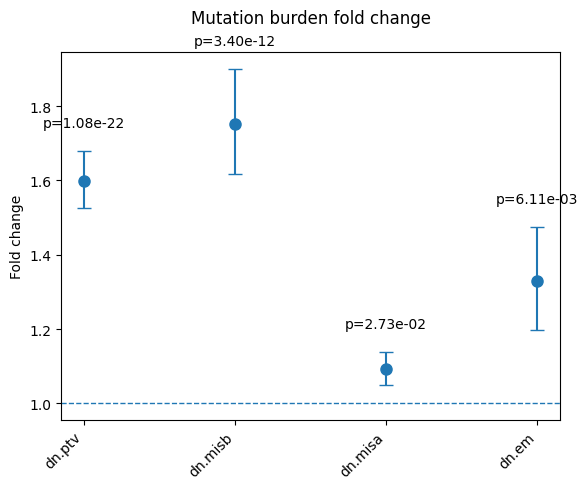

In [ ]:
# x positions
x = np.arange(len(results_df))
y = results_df["fc"].values

# asymmetric error bars
yerr = np.vstack([
    results_df["err_lower"].values,
    results_df["err_upper"].values
])

fig, ax = plt.subplots(figsize=(6, 5))

ax.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o",
    capsize=5,
    markersize=8,
    linewidth=1.5
)

# reference line at no enrichment
ax.axhline(1, linestyle="--", linewidth=1)

ax.set_xticks(x)
ax.set_xticklabels(results_df["mut_type"], rotation=45, ha="right")
ax.set_ylabel("Fold change")
ax.set_title("Mutation burden fold change\n")

# annotate p-values
for i, row in results_df.iterrows():
    y_text = row["fc"] + row["err_upper"] + 0.03 * np.nanmax(y + results_df["err_upper"].values)
    ax.text(
        i,
        y_text,
        f"p={row['pval']:.2e}",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [612]:
results_df

,mut_type,fc,err_lower,err_upper,pval
0,dn.ptv,1.599416,0.074809,0.078480,1.080824e-22
1,dn.misb,1.752824,0.135792,0.147195,3.401980e-12
2,dn.misa,1.093695,0.043487,0.045288,2.728834e-02
3,dn.em,1.329274,0.131075,0.145414,6.110918e-03


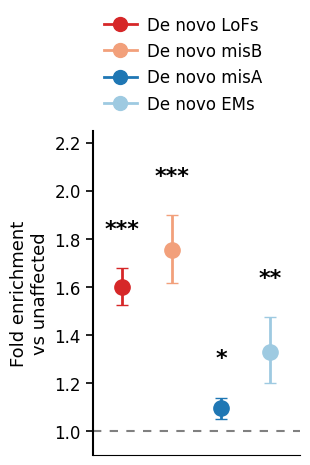

In [ ]:


# order and labels
order = ["dn.ptv", "dn.misb", "dn.misa", "dn.em"]
label_map = {
    "dn.ptv": "De novo LoFs",
    "dn.misb": "De novo misB",
    "dn.misa": "De novo misA",
    "dn.em": "De novo EMs"
}

# colors similar to your example
color_map = {
    "dn.ptv": "#d62728",   # red
    "dn.misb": "#f2a07b",  # peach
    "dn.misa": "#1f77b4",  # blue
    "dn.em": "#9ecae1"     # light blue
}

results_df["mut_type"] = pd.Categorical(results_df["mut_type"], categories=order, ordered=True)
results_df = results_df.sort_values("mut_type").reset_index(drop=True)

# x positions
x = np.arange(len(results_df))

fig, ax = plt.subplots(figsize=(3.2, 5))

# plot each point with asymmetric error bars
for i, row in results_df.iterrows():
    ax.errorbar(
        x[i],
        row["fc"],
        yerr=np.array([[row["err_lower"]], [row["err_upper"]]]),
        fmt='o',
        markersize=11,
        capsize=4,
        elinewidth=2,
        color=color_map[row["mut_type"]],
        markerfacecolor=color_map[row["mut_type"]],
        markeredgecolor=color_map[row["mut_type"]],
        zorder=3
    )

# horizontal reference line at 1
ax.axhline(1, color="gray", linestyle="--", linewidth=1.5, dashes=(4, 4), zorder=1)

# significance stars
def p_to_stars(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    else:
        return ""

for i, row in results_df.iterrows():
    stars = p_to_stars(row["pval"])
    if stars:
        y_text = row["fc"] + row["err_upper"] + 0.12
        ax.text(x[i], y_text, stars, ha="center", va="bottom", fontsize=16, fontweight="bold")

# axes formatting
ax.set_xlim(-0.6, len(results_df)-0.4)
ax.set_ylim(0, max(results_df["fc"] + results_df["err_upper"]) + 0.6)
ax.set_xticks([])

ax.set_ylabel("Fold enrichment\nvs unaffected", fontsize=13)

# clean spines
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)

ax.tick_params(axis="y", labelsize=12, width=1.2, length=5)
ax.tick_params(axis="x", length=0)

# legend
handles = [
    plt.Line2D([0], [0], marker='o', color=color_map[m], linestyle='-',
               markersize=10, linewidth=2, label=label_map[m])
    for m in order
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(-0.02, 1.4),
          frameon=False, fontsize=12, handletextpad=0.6)

# # panel label "C"
# ax.text(-0.95, ax.get_ylim()[1]*0.96, "C", fontsize=20, fontweight="bold", va="top")
plt.ylim(0.9, 2.25)

plt.tight_layout()
plt.savefig(f"{folder_path}figures/figures/Fig1c.pdf", dpi=300)
plt.show()